# NASA EPSCoR Progress: Characterization of Isolated EOM Performance
### 20261023 - *Tyndale Stutzman*
---

## Introduction:

This notebook aims to diagnose the performance of a repaired EOM against that of a fully functioning one. More specifically, the EOM to be characterized is a [Newport 4004](https://api.p1.mks.com/medias/sys_master/images/images/h65/hcc/8797007839262/400X-and-406X-User-Manual-Rev-J.pdf) modulator, compared against a [Thorlabs EO-PM-NR-C1 EOM](https://www.thorlabs.com/item/EO-PM-NR-C1). In the process of preparing the 4004 to accomodate temperature stabilizing components, the crystal was removed, inadvertently breaking the wire bonded electrodes. To fix this, 1mil platinum wire was manually bonded to the crystal with [Leitsilber 200](https://www.fishersci.com/shop/products/leitsilver/NC9368358) silver cement. Before building this notebook, the EOM has been demonstrated to function as expected, up to a few $\text{ kHz}$, however behavior beyond that limit is unknown. A few photos of the manual wire bonded repair are below.<!-- 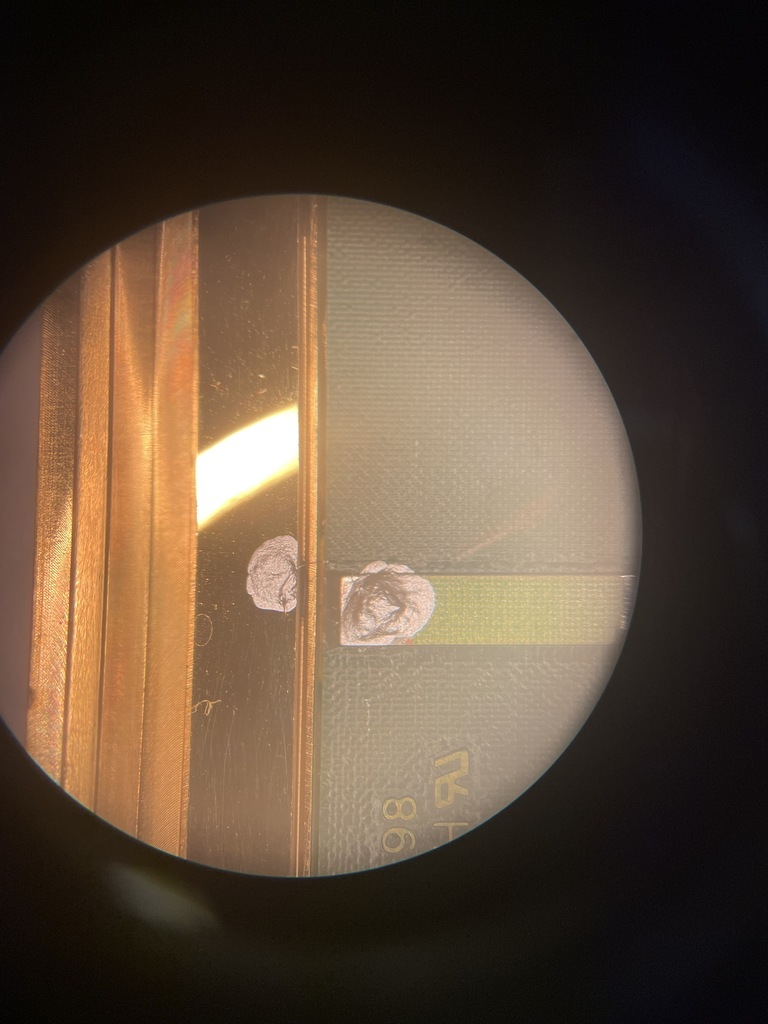 -->

## Table of Contents

1. [Background](#background)
1. [Setup](#setup)
   1. [Environment & Packages](#env)
   1. [Parameter Configuration](#conf)
   1. [Connect Devices](#connect)
      1. [Red Pitaya](#rp)
      1. [PAX Polarimeter](#pax)
1. [Characterization](#char)
   1. [Electrical Drive Verification](#vdrive)
   1. [$V_{\pi}$ & Hysteresis](#vpi)
   1. [Frequency Response](#freq)
   1. [Stability & Drift](#drift)
1. [Jones Matrix Measurements](#jones)
1. [Save Data](#save)
1. [Analysis](#analysis)


<a id="setup"></a>
## Setup


<a id="env"></a>
### Environment & Packages

To get started, enter the appropriate repository environment and run this notebook from this local folder, `notebooks/`.

In [ ]:
import sys
from pathlib import Path
from importlib.metadata import version

src = (Path("python") if Path("python").is_dir() else Path("../python")).resolve()
assert (src / "instruments").is_dir(), "Start in the repo root or notebooks/"
for directory in (src, src.parent):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))

print(f"Python {sys.version.split()[0]} | {sys.executable}")
print({name: version(name) for name in ("numpy", "scipy", "pyrpl", "yaqc")})

<a id="conf"></a>
### Parameter Configuration

These are intended bench settings and operator declarations, not instrument readbacks.
OUT1 drives the preamp → 3211 → EOM; OUT2 is unused. The confirmed RP ceiling is
±0.9 V, with zero DC bias. The gain and voltage windows below use the confirmed bench settings;
remaining nominal offsets, polarity and margins come from `scripts/eom_raw_capture.json`.
Review those assumptions and set each `bench_confirmed` flag only after checking the bench. Numeric values
use the units in their names. The thermistor resistance is not a temperature calibration.
`monitor_calibration` records the measured OUT1-command → IN2 relationship for ±0.3 V,
at DC and 0.4656612873 Hz. It predicts monitor voltage; the ×30 electrode conversion
remains nominal. Each new run saves its own calibration snapshot and source run.
After changing these settings, rerun the affected experiment's settings and acquisition cells.

In [49]:
# Instrument connections; the key pin comes from the existing EOM tool.
rp_hostname = "192.168.1.98"
rp_config = "scope_config"
ssh_host_key_sha256 = "W5g8Qcvu7r+8mMQZInHzNLpvOpYsvnCvo5hwYkWJCRY"
frequency_correction = 1.0  # Existing nominal clock assumption, not a measurement.
pax_daemon_config_path = src / "polarization_locking/hardware/pax1000.toml"

# Optical conditions and the EOM currently installed.
wavelength_nm = 830.0
eom_under_test = "Newport 4004 EOM"
temperature_conditions = "Stabilized at 10.07kOhms"
thermistor_resistance_ohm = 10070.0  # Reported resistance; no conversion to degrees.

rp_inputs = {
    "in1": {"signal": "photodiode", "full_scale_v": 1.0},
    "in2": {"signal": "drive monitor", "full_scale_v": 20.0},
}
rp_outputs = {
    "out1": {"signal": "preamp -> 3211 -> EOM", "command_limits_v": [-0.9, 0.9]},
    "out2": {"signal": "unused", "command_limits_v": None},
}

# Confirmed voltage windows; frequency spans one nominal ASG step to the existing tool ceiling.
limits = {
    "amplifier_input_v": [-5.0, 5.0],
    "electrode_v": [-200.0, 200.0],  # 3211 output working limit, not an EOM damage rating.
    "monitor_adc_v": [-6.0, 6.0],
    "frequency_hz": [125_000_000 * frequency_correction / 2**30, 10_000.0],
    "ac_peak_command_max_v": 0.9,  # Operator ceiling at RP OUT1; downstream limits also apply.
}
# Nominal offsets, polarity and engineering margins below are reused from eom_raw_capture.json;
# they remain assumptions to review, not new calibration measurements.
chain = {
    "preamp_gain": 8.89,  # Existing setting; not independently calibrated here.
    "preamp_offset_v": 0.0,  # An assumption until verified.
    "amplifier_input_margin_v": 0.5,
    "electrode_gain_per_command_v": 8.89 * 40.0,  # Confirmed nominal preamp × 3211 gains.
    "electrode_offset_v": 0.0,
    "electrode_margin_v": 20.0,
    "monitor_scale_v_per_v": 30.0,  # Confirmed nominal electrode V / monitor V.
    "monitor_zero_v": 0.0,
    "monitor_polarity": 1,
    "monitor_conversion_calibrated": False,
    "monitor_conversion_evidence": "Nominal 3211 gain ×40 and monitor ×30 confirmed; no absolute calibration",
    "monitor_disagreement_electrode_v": 50.0,
}

# Empirical OUT1-command -> IN2 prediction; nominal electrode conversion stays in chain.
monitor_calibration = {
    "gain_v_per_v": 9.644207411279817,
    "offset_v": -0.0681210879017325,
    "command_range_v": [-0.3, 0.3],
    "sine_frequency_hz": 0.46566128730773926,
    "source_run": "experiments/_local/command_monitor_calibration_20261027T201314Z_b468db58",
}

# Same physical preconditions as the standalone EOM tool. Do not auto-confirm.
bench_confirmed = {
    "wiring_and_optics": True,  # Check the present connections and optical path.
    "adc_jumpers": True,  # Operator reported IN1/LV and IN2/HV.
    "chain_model_and_limits": True,  # Review the nominal gains, offsets, polarity and margins above.
    "independent_hardware_protection": True,  # External protection; Python is not a hardware interlock.
    "zero_startup_profile": True,  # Bench tolerates FPGA initialization before zero/off writes.
    "exclusive_rp_access": True,  # No other notebook, GUI or runner controls the RP.
}
capture_timeout_s = 15.0
pax_measurement_wait_s = 0.06
pax_fresh_read_timeout_s = 5.0
results_directory = src.parent / "experiments" / "_local"

<a id="connect"></a>
### Connect Devices

This experiment uses the Red Pitaya and the Thorlabs PAX polarimeter. 

<a id="RP"></a>
#### Red Pitaya

In [50]:
# Refresh the edited wrapper after closing this notebook's previous connection.
from importlib import reload
import instruments.red_pitaya as rp_interface

if "rp" in globals():
    rp.close()
RedPitaya = reload(rp_interface).RedPitaya
rp = RedPitaya(rp_hostname, profile=rp_config)
rp.attach_monitor()  # Smoke test only: does not initialize drive outputs.
rp.read_status()

{'host': '192.168.1.98',
 'mode': 'monitor_only',
 'monitor_port': 2223,
 'preferred_monitor_port': 2223,
 'scope_registers': {'0x40100004': 0,
  '0x40100010': 16384,
  '0x40100014': 16384,
  '0x40100028': 0,
  '0x40380000': 10,
  '0x40390000': 11},
 'requested_monotonic_s': 93381.193779767,
 'received_monotonic_s': 93381.195317683,
 'received_utc': '2026-10-27T20:50:46.174541+00:00'}

<a id="PAX"></a>
#### PAX Polarimeter

In [51]:
from importlib import reload
import instruments.pax as pax_interface

PAX = reload(pax_interface).PAX
with PAX.local_session(config_path=pax_daemon_config_path,
                       measurement_wait_s=pax_measurement_wait_s) as pax:
    pax.set_wavelength(wavelength_nm)
    display(pax.read_status())
    pax_raw = pax.read_fresh(timeout_s=pax_fresh_read_timeout_s)

pax_raw

Starting local PAX daemon (includes 5 s motor settling)...
PAX session ready at 127.0.0.1:38400 (serial M01303584).


{'host': '127.0.0.1',
 'port': 38400,
 'identity': {'name': 'thorlabs-pax1000',
  'kind': 'thorlabs-pax1000',
  'make': None,
  'model': 'PAX1000IR1',
  'serial': 'M01303584'},
 'wavelength_nm': 830.0,
 'channel_units': {'revisions': None,
  'timestamp': None,
  'adc_min': None,
  'adc_max': None,
  'rev_time': None,
  'theta': 'radian',
  'eta': 'radian',
  'dop': None,
  'ptotal': None}}

PAX daemon exited; motor-stop command and USB close succeeded.


{'revisions': 2354.0,
 'timestamp': 6780204.0,
 'adc_min': 4000.0,
 'adc_max': 4720.0,
 'rev_time': 0.01669685,
 'theta': -0.6062306,
 'eta': -0.1417769,
 'dop': 3.051795,
 'ptotal': 3.409278e-11,
 'measurement_id': 2}

<a id="char"></a>
## EOM Characterization

The objective of the following experiments is to determine the performance capabilities of the repaired Newport 4004 EOM. This will aid in the development of calibration measurements for the development of the high-speed dual-EOM polarimeter. 

<a id="vdrive"></a>
### Electrical Drive Verification

First capture **one bounded sine** on OUT1 while recording PD/IN1 and monitor/IN2
in the same frozen scope buffer. This is a drive-chain diagnostic, not an EOM
performance verdict or a calibrated electrode-voltage measurement.

Fill the local command values below and the global approved bounds/conversions.
`peak_v` is **peak RP command amplitude**, not peak-to-peak or electrode volts.
The active connection can initialize the FPGA/primary monitor and clears competing
output routes; exclusive RP access and independent hardware protection are required.
The earlier passive smoke-test connection is closed before active initialization.
No PAX session is needed for this capture.

On completion, error or Ctrl-C, the active session attempts to disable routes and
set both RP outputs to DC zero. Register readback does not establish measured zero
HV. Raw data and metadata are retained locally, including failed/partial captures.
Run the inspection cell separately after acquisition. It plots unmodified input-voltage
traces and reports an explicit IN2 sine fit against the saved command-to-monitor calibration. Compare the same settings with each EOM installed, retaining both runs.

In [52]:
# Local test settings: choose these deliberately after checking the bench.
electrical_test = {
    "offset_v": 0.0,              # RP OUT1 DC bias [V]
    "peak_v": 0.3,                # RP OUT1 sine amplitude [V peak, not peak-to-peak]
    "frequency_hz": 0.5,          # Requested sine frequency [Hz]; hardware rounds it

    "ramp_s": 0.2,                 # Requested time to ramp the DC bias
    "settle_s": 0.5,               # Wait after applying the waveform, before capture
    "min_cycles": 4.0,             # Minimum drive cycles within one capture
    "min_samples_per_cycle": 32,   # Minimum captured samples per drive cycle
}

# Preview only; acquisition uses the instrument readback below.
from scripts.eom_raw_capture import sampling
requested_hz = electrical_test["frequency_hz"]
step_hz = 125_000_000 * frequency_correction / 2**30
preview_hz = round(requested_hz / step_hz) * step_hz
print(f"Requested: {requested_hz:.10f} Hz | nominal preview: {preview_hz:.10f} Hz")
preview_config = {"frequency_correction": frequency_correction,
                  "capture_timeout_s": capture_timeout_s, "dynamic": electrical_test}
try:
    preview_decimation, preview_dt = sampling(preview_config, preview_hz)
    print(f"Capture preview: {1/preview_dt:.6f} samples/s, "
          f"{16384*preview_dt:.6f} s, {preview_hz*16384*preview_dt:.3f} cycles")
except ValueError as error:
    print(f"Capture cannot fit: {error}")

# Recheck current globals on EVERY acquisition; no hardware calls in this function.
def electrical_config(*, sine=True):
    from copy import deepcopy
    import numpy as np
    from scripts.eom_raw_capture import envelope, sampling

    required = {"wiring_and_optics", "adc_jumpers", "chain_model_and_limits",
                "independent_hardware_protection", "zero_startup_profile", "exclusive_rp_access"}
    if set(bench_confirmed) != required:
        raise ValueError("Keep the six bench_confirmed fields; verify each on the bench.")
    c = deepcopy({"limits": dict(limits, command_v=rp_outputs["out1"]["command_limits_v"]),
                  "chain": chain, "monitor_calibration": monitor_calibration,
                  "test": electrical_test if sine else {}, "inputs": rp_inputs,
                  "frequency_correction": frequency_correction, "capture_timeout_s": capture_timeout_s,
                  "hardware": {"eom": eom_under_test, "wavelength_nm": wavelength_nm,
                               "temperature_conditions": temperature_conditions,
                               "thermistor_resistance_ohm": thermistor_resistance_ohm},
                  "confirmed": bench_confirmed, "rp_hostname": rp_hostname, "rp_config": rp_config,
                  "ssh_host_key_sha256": ssh_host_key_sha256})
    missing = [f"{section}.{k}" for section in ("limits", "chain", "test")
               for k, v in c[section].items() if v is None]
    unconfirmed = [f"bench_confirmed.{k}" for k, v in bench_confirmed.items() if v is not True]
    if missing or unconfirmed:
        raise ValueError("Complete physical bench settings before connecting:\n  " +
                         "\n  ".join(missing + unconfirmed))
    pairs = [c["limits"][k] for k in ("command_v", "amplifier_input_v", "electrode_v", "monitor_adc_v", "frequency_hz")]
    if any(not isinstance(p, (list, tuple)) or len(p) != 2 for p in pairs):
        raise ValueError("Each voltage/frequency bound must be [minimum, maximum].")
    numeric_chain = [v for k, v in c["chain"].items() if k not in ("monitor_conversion_calibrated", "monitor_conversion_evidence")]
    numbers = [*numeric_chain, *c["test"].values(), *(v for p in pairs for v in p),
               c["limits"]["ac_peak_command_max_v"], c["frequency_correction"], c["capture_timeout_s"], c["hardware"]["wavelength_nm"], *(c["inputs"][k]["full_scale_v"] for k in ("in1", "in2"))]
    if any(isinstance(v, bool) for v in numbers) or not np.isfinite(np.asarray(numbers, dtype=float)).all():
        raise ValueError("Numeric settings must be finite numbers, not flags.")
    if any(p[0] >= p[1] for p in pairs):
        raise ValueError("Every lower bound must be less than its upper bound.")
    ch, t = c["chain"], c["test"]
    positive = (ch["monitor_scale_v_per_v"], ch["amplifier_input_margin_v"], ch["electrode_margin_v"],
                ch["monitor_disagreement_electrode_v"], c["frequency_correction"], c["capture_timeout_s"], c["hardware"]["wavelength_nm"])
    if min(positive) <= 0 or ch["preamp_gain"] == 0 or ch["electrode_gain_per_command_v"] == 0 or ch["monitor_polarity"] not in (-1, 1):
        raise ValueError("Check chain gains, polarity, positive margins and timing.")
    if sine and (t["peak_v"] <= 0 or min(t["ramp_s"], t["settle_s"]) < 0 or t["min_cycles"] < 3 or t["min_samples_per_cycle"] < 16):
        raise ValueError("Use a positive sine peak, nonnegative waits, >=3 cycles and >=16 samples per cycle.")
    if set(c["inputs"]) != {"in1", "in2"} or [c["inputs"][k]["full_scale_v"] for k in ("in1", "in2")] != [1.0, 20.0]:
        raise ValueError("This notebook assumes the reported IN1/LV and IN2/HV wiring.")
    if sine:
        envelope(c, t["offset_v"], t["peak_v"], t["frequency_hz"])
        c["dynamic"] = {k: t[k] for k in ("min_cycles", "min_samples_per_cycle")}
        step = 125_000_000 * c["frequency_correction"] / 2**30
        planned_frequency = round(t["frequency_hz"] / step) * step
        envelope(c, t["offset_v"], t["peak_v"], planned_frequency)
        sampling(c, planned_frequency)  # Reject impossible timing before connecting.
    c["adc_full_scale_v"] = [c["inputs"][k]["full_scale_v"] for k in ("in1", "in2")]
    return c


Requested: 0.5000000000 Hz | nominal preview: 0.4656612873 Hz
Capture preview: 1907.348633 samples/s, 8.589935 s, 4.000 cycles


In [53]:
import json, sys, time
from datetime import datetime, timezone
from uuid import uuid4
import numpy as np
from scripts.eom_raw_capture import sampling, check_capture

run_directory = None  # A failed preflight must not leave a previous run selected.
c = electrical_config()  # Fails before connecting if the bench settings are incomplete.
t = c["test"]
drive = RedPitaya.drive_session(
    c["rp_hostname"], profile=c["rp_config"], ssh_host_key_sha256=c["ssh_host_key_sha256"],
    command_limits_v={"out1": c["limits"]["command_v"]}, frequency_limits_hz=c["limits"]["frequency_hz"],
    max_peak_v=c["limits"]["ac_peak_command_max_v"], frequency_correction=c["frequency_correction"])
run_directory = results_directory / ("electrical_drive_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ_") + uuid4().hex[:8])
run_directory.mkdir(parents=True, exist_ok=False)
raw_path = run_directory / "raw.npz"
record = {"status": "running", "started_utc": datetime.now(timezone.utc).isoformat(), "config": c,
          "python": sys.version, "packages": {name: version(name) for name in ("numpy", "pyrpl")},
          "source_text": {name: path.read_text() for name, path in {
              "rp_drive.py": src / "instruments/_rp_drive.py", "red_pitaya.py": src / "instruments/red_pitaya.py",
              "eom_raw_capture.py": src.parent / "scripts/eom_raw_capture.py"}.items()},
          "acquisition_cell": globals().get("_ih", ["Not available outside IPython"])[-1]}
(run_directory / "metadata.json").write_text(json.dumps(record, indent=2, allow_nan=False))
try:
    if "rp" in globals():
        rp.close()  # Release this notebook's passive monitor before active initialization.
    with drive:
        command = drive.set_waveform("out1", offset_v=t["offset_v"], peak_v=t["peak_v"],
                                     frequency_hz=t["frequency_hz"], ramp_s=t["ramp_s"])
        time.sleep(t["settle_s"])
        drive_frequency_hz = command["actual"]["frequency_hz"]  # Use this for demodulation too.
        decimation, planned_dt = sampling(c, drive_frequency_hz)
        print(f"OUT1 frequency: requested {t['frequency_hz']:.10f}, readback {drive_frequency_hz:.10f} Hz")
        print(f"Capturing IN1 + IN2: {1/planned_dt:.6f} samples/s, "
              f"{16384*planned_dt:.6f} s, {drive_frequency_hz*16384*planned_dt:.3f} cycles", flush=True)
        capture = drive.capture(decimation=decimation,
                                full_scale_v={k: c["inputs"][k]["full_scale_v"] for k in ("in1", "in2")},
                                timeout_s=c["capture_timeout_s"])
    # Outputs are now zero/off; retain raw data BEFORE clipping/monitor checks.
    np.savez_compressed(raw_path, raw_counts=capture["raw_counts"], time_s=capture["time_s"])
    if capture["metadata"]["issues"]:
        raise RuntimeError("; ".join(capture["metadata"]["issues"]))
    check_meta = dict(capture["metadata"], asg_after=capture["metadata"]["asg_after"]["out1"])
    point = {"decimation": decimation, "sample_interval_s": planned_dt * c["frequency_correction"]}
    record["input_summary"] = check_capture(capture["raw_counts"], check_meta, point, command["actual"], c)
    record["status"] = "completed"
except BaseException as error:
    record.update(status="interrupted" if isinstance(error, KeyboardInterrupt) else "failed",
                  error=f"{type(error).__name__}: {error}")
    raise
finally:
    captured = drive.last_capture or {}
    if not raw_path.exists() and captured:
        keys = ("raw_counts", "time_s") if "raw_counts" in captured else ("raw_in1", "raw_in2")
        arrays = {k: captured[k] for k in keys if k in captured}
        if arrays:
            np.savez_compressed(raw_path, **arrays)  # Also retain partial/failed reads.
    record.update(connection=drive.connection_evidence, command=drive.last_command,
                  capture=captured.get("metadata"), cleanup=drive.cleanup_evidence,
                  finished_utc=datetime.now(timezone.utc).isoformat())
    (run_directory / "metadata.json").write_text(json.dumps(record, indent=2, allow_nan=False))
    print(f"{record['status']}; cleanup={record['cleanup']['status']}; saved to {run_directory}")


INFO:pyrpl.redpitaya:Correct FPGA image detected, skipping reload
INFO:pyrpl.redpitaya:Successfully connected to Redpitaya with hostname 192.168.1.98.


OUT1 frequency: requested 0.5000000000, readback 0.4656612873 Hz
Capturing IN1 + IN2: 1907.348633 samples/s, 8.589935 s, 4.000 cycles
completed; cleanup=COMPLETED; saved to /home/augustus/Documents/code/repos/epscor-project-tools/experiments/_local/electrical_drive_20261027T205054Z_5f85e974


IN2 sine fit: 2.891946 V peak, -0.068936 V offset
Calibrated prediction: 2.892556 V peak, -0.068121 V offset
Peak difference: -0.021% | source: experiments/_local/command_monitor_calibration_20261027T201314Z_b468db58


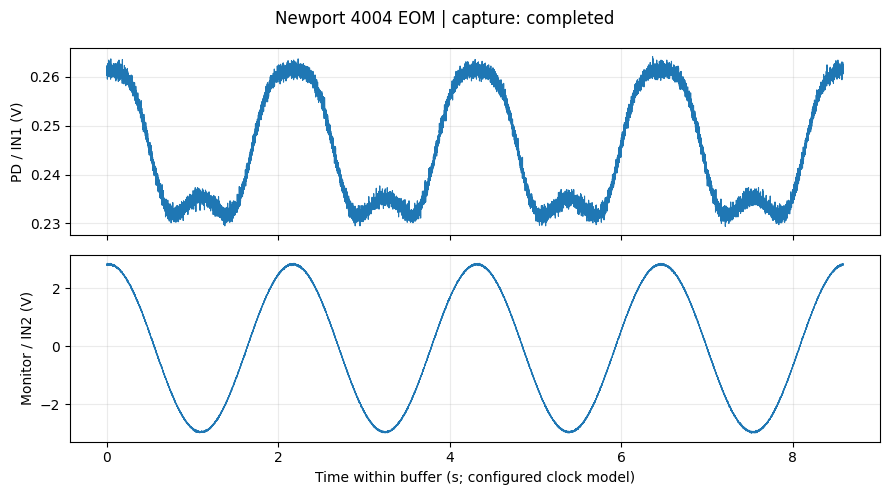

In [54]:
# Inspect only: this cell issues no instrument commands.
import matplotlib.pyplot as plt

if not globals().get("run_directory"):
    raise RuntimeError("No current run: complete the acquisition preflight first.")
saved_record = json.loads((run_directory / "metadata.json").read_text())
with np.load(run_directory / "raw.npz", allow_pickle=False) as saved:
    if "raw_counts" not in saved:
        raise RuntimeError(f"Only partial data were saved: {saved.files}. Inspect those arrays explicitly.")
    counts = saved["raw_counts"]
    time_s = saved["time_s"]
full_scale = np.array([saved_record["config"]["inputs"][k]["full_scale_v"] for k in ("in1", "in2")])
input_volts = counts.astype(float) / 8192 * full_scale[:, None]
# Fit all IN2 samples at the saved frequency; raw traces below stay unmodified.
cal = saved_record["config"].get("monitor_calibration")
actual = saved_record["command"]["actual"]
if cal:
    phase = 2 * np.pi * actual["frequency_hz"] * time_s
    basis = np.column_stack([np.ones(len(time_s)), np.sin(phase), np.cos(phase)])
    coefficients = np.linalg.lstsq(basis, input_volts[1], rcond=None)[0]
    measured_peak = np.hypot(*coefficients[1:])
    print(f"IN2 sine fit: {measured_peak:.6f} V peak, {coefficients[0]:+.6f} V offset")
    in_range = (cal["command_range_v"][0] <= actual["offset_v"] - actual["amplitude_v"] and
                actual["offset_v"] + actual["amplitude_v"] <= cal["command_range_v"][1] and
                np.isclose(actual["frequency_hz"], cal["sine_frequency_hz"], rtol=1e-9, atol=0))
    if in_range:
        expected_peak = abs(cal["gain_v_per_v"]) * actual["amplitude_v"]
        expected_offset = cal["gain_v_per_v"] * actual["offset_v"] + cal["offset_v"]
        print(f"Calibrated prediction: {expected_peak:.6f} V peak, {expected_offset:+.6f} V offset")
        print(f"Peak difference: {100*(measured_peak/expected_peak - 1):+.3f}% | source: {cal['source_run']}")
    else:
        print("Outside the calibration's tested command range/frequency; prediction comparison skipped.")
else:
    print("This run predates the saved command-to-monitor calibration.")

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(9, 5))
for ax, values, label in zip(axes, input_volts, ("PD / IN1 (V)", "Monitor / IN2 (V)")):
    ax.plot(time_s, values, linewidth=0.8)
    ax.set_ylabel(label)
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("Time within buffer (s; configured clock model)")
fig.suptitle(f"{saved_record['config']['hardware']['eom']} | capture: {saved_record['status']}")
fig.tight_layout()
plt.show()


<a id="vpi"></a>
### $V_{\pi}$ & Hysteresis: cycling calibration

Grow a sine near **1 Hz** until both directions show a resolved bright/dark pair.
Then center on that pair, go **20% past** it, and repeat until each branch's $V_{\pi}$
estimate varies by at most **0.01 V over three captures**. Report the branches separately.
The combined bias + peak stays within **±0.5 V RP**, within the [3211 input limit](https://api.p1.mks.com/medias/sys_master/images/images/hcd/h1d/8797005316126/3211-User-Manual-RevB.pdf) with the current preamp.
Each capture lasts **8.59 s** (about nine cycles); the sine is reconfigured between trials.

$V_{\pi}$ is the adjacent bright/dark **voltage separation**, not the sine's peak amplitude.
Voltage coordinates are **RP-equivalent estimates from ASG amplitude and IN2 phase**,
assuming positive linear low-frequency drive transfer and a sinusoidal optical fringe.
PD is never phase-shifted to force branch agreement. Binned means and quadratic extrema
are explicit processing; all raw samples are saved. Convergence tests repeatability, not absolute accuracy.


In [ ]:
# RP volts and seconds. The cap includes BOTH bias and AC peak.
cycle_test = {
    "frequency_hz": 1.0,         # Request; Pyrpl readback is normally 1.0477378964 Hz.
    "offset_v": 0.0, "start_peak_v": 0.10, "max_abs_v": 0.50,
    "growth": 1.5, "overshoot": 1.2,
    "ramp_s": 0.5, "settle_s": 2.0,  # Bias ramp; sine is reconfigured between trials.
    "decimation": 65536,         # 16,384 samples over 8.589934592 s.
    "tolerance_v": 0.01, "stable_captures": 3, "max_trials": 12,
    "min_fringe_v": 0.005,       # Minimum resolved bright/dark PD difference: 5 mV.
}


In [ ]:
# Process only: 64 voltage bins per direction; no raw samples are altered or discarded.
def estimate_cycle_vpi(capture, actual, min_fringe_v=0.005):
    import numpy as np
    from scipy.signal import find_peaks
    time_s, inputs = capture["time_s"], capture["input_volts"]
    phase = 2*np.pi*actual["frequency_hz"]*time_s
    basis = np.column_stack([np.ones(len(phase)), np.sin(phase), np.cos(phase)])
    coefficients = np.linalg.lstsq(basis, inputs[1], rcond=None)[0]
    monitor_sine = basis[:, 1:] @ coefficients[1:]
    monitor_peak = float(np.hypot(*coefficients[1:]))
    monitor_residual = float(np.std(inputs[1] - basis @ coefficients))
    result = {"usable": False, "branches": {}, "monitor_peak_v": monitor_peak,
              "monitor_offset_v": float(coefficients[0]), "monitor_residual_rms_v": monitor_residual}
    if monitor_peak <= 0 or monitor_residual > 0.03*monitor_peak:
        return dict(result, reason="IN2 is too noisy/distorted for a sine phase reference")
    # RP-equivalent coordinate: ASG amplitude plus IN2 phase, assuming positive linear low-frequency transfer.
    command_v = actual["offset_v"] + actual["amplitude_v"]*monitor_sine/monitor_peak
    increasing = coefficients[1]*np.cos(phase) - coefficients[2]*np.sin(phase) > 0
    edges = np.linspace(actual["offset_v"]-actual["amplitude_v"], actual["offset_v"]+actual["amplitude_v"], 65)
    labels = np.clip(np.searchsorted(edges, command_v, side="right")-1, 0, 63)  # Bin indices only.
    for direction, selected in (("up", increasing), ("down", ~increasing)):
        counts = np.bincount(labels[selected], minlength=64)
        if np.any(counts < 3):
            result["branches"][direction] = {"reason": "insufficient samples in a voltage bin"}
            continue
        x = np.bincount(labels[selected], weights=command_v[selected], minlength=64)/counts
        y = np.bincount(labels[selected], weights=inputs[0, selected], minlength=64)/counts
        branch = {"x_v": x.tolist(), "pd_mean_v": y.tolist(), "counts": counts.tolist()}
        result["branches"][direction] = branch
        # Require a resolved max/min, >=5 mV contrast, and a near-sinusoidal intensity fringe.
        prominence = max(0.0001, 0.005*float(np.ptp(y)))
        maxima = find_peaks(y, prominence=prominence)[0]
        minima = find_peaks(-y, prominence=prominence)[0]
        extrema = sorted([(int(i), 1) for i in maxima] + [(int(i), -1) for i in minima])
        pairs = [(a[0], b[0]) for a, b in zip(extrema[:-1], extrema[1:])
                 if a[1] != b[1] and abs(y[b[0]]-y[a[0]]) >= min_fringe_v]
        if not pairs:
            branch["reason"] = "no resolved adjacent interior bright/dark pair"
            continue
        pair = max(pairs, key=lambda ij: abs(y[ij[1]]-y[ij[0]]))
        vertices = []
        for i in pair:
            lo, hi = max(0, i-3), min(len(x), i+4)
            parabola = np.polyfit(x[lo:hi]-x[i], y[lo:hi], 2)
            vertex = x[i]-parabola[1]/(2*parabola[0]) if parabola[0] else x[i]
            if not x[lo] <= vertex <= x[hi-1] or ((parabola[0] < 0) != (i in maxima)):
                vertex = x[i]  # Retain the bin location if the local quadratic is unsupported.
            vertices.append(float(vertex))
        width = abs(vertices[1]-vertices[0])
        if width < 4*np.mean(np.diff(x)):
            branch["reason"] = "fringe is undersampled by the voltage bins"
            continue
        model = np.column_stack([np.ones(len(x)), np.sin(np.pi*x/width), np.cos(np.pi*x/width)])
        fitted = model @ np.linalg.lstsq(model, y, rcond=None)[0]
        shape_error = float(np.sqrt(np.mean((y-fitted)**2)))
        branch.update(extrema_v=vertices, model_rms_v=shape_error,
                      bright_v=vertices[0] if pair[0] in maxima else vertices[1],
                      dark_v=vertices[1] if pair[0] in maxima else vertices[0])
        if shape_error > 0.05*np.ptp(y):
            branch["reason"] = "resolved features do not match a sinusoidal fringe closely enough"
            continue
        branch["vpi_v"] = float(width)  # A quadratic-interpolated spacing, not a measured terminal voltage.
    result["usable"] = all("vpi_v" in result["branches"].get(d, {}) for d in ("up", "down"))
    result["reason"] = "resolved on both branches" if result["usable"] else "; ".join(
        d+": "+result["branches"].get(d, {}).get("reason", "unresolved") for d in ("up", "down"))
    return result

cycle_analysis_definition = globals().get("_ih", ["Not available outside IPython"])[-1]


In [ ]:
# Hardware loop: increase amplitude, then center on a resolved pair and refine.
import json, sys, time
from datetime import datetime, timezone
from uuid import uuid4
import numpy as np
from scripts.eom_raw_capture import envelope, sampling, check_capture, write_json

cycle_directory = None
c = electrical_config(sine=False)
s = cycle_test.copy()
if (any(isinstance(v, bool) for v in s.values()) or not np.isfinite(list(s.values())).all() or
        not 0 < s["start_peak_v"] <= s["max_abs_v"] or abs(s["offset_v"])+s["start_peak_v"] > s["max_abs_v"] or
        min(s["growth"], s["overshoot"]) <= 1 or min(s["ramp_s"], s["settle_s"]) < 0 or
        min(s["tolerance_v"], s["min_fringe_v"]) <= 0 or
        any(type(s[k]) is not int for k in ("decimation", "stable_captures", "max_trials")) or
        not 2 <= s["stable_captures"] <= s["max_trials"]):
    raise ValueError("Check finite settings, amplitude bounds, growth/overshoot >1 and positive convergence settings.")
c["test"], c["dc"] = s, {"decimation": s["decimation"]}
for endpoint in (-s["max_abs_v"], s["max_abs_v"]):
    envelope(c, endpoint)  # Keep the complete allowed window inside the 3211/bench limits.
envelope(c, s["offset_v"], s["start_peak_v"], s["frequency_hz"])
c["limits"]["command_v"] = [-s["max_abs_v"], s["max_abs_v"]]
decimation, sample_dt = sampling(c)
step_hz = 125e6*c["frequency_correction"]/2**30
preview_hz = round(s["frequency_hz"]/step_hz)*step_hz
envelope(c, s["offset_v"], s["start_peak_v"], preview_hz)
if preview_hz*16384*sample_dt < 3 or preview_hz*sample_dt > 1/64:
    raise ValueError("Capture needs >=3 cycles and >=64 samples/cycle.")
print(f"Sine preview {preview_hz:.10f} Hz | {16384*sample_dt:.6f} s/capture | RP window ±{s['max_abs_v']:g} V", flush=True)
drive = RedPitaya.drive_session(c["rp_hostname"], profile=c["rp_config"], ssh_host_key_sha256=c["ssh_host_key_sha256"],
    command_limits_v={"out1": c["limits"]["command_v"]}, frequency_limits_hz=c["limits"]["frequency_hz"],
    max_peak_v=min(s["max_abs_v"], c["limits"]["ac_peak_command_max_v"]), frequency_correction=c["frequency_correction"])
cycle_directory = results_directory / ("cycling_vpi_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ_") + uuid4().hex[:8])
cycle_directory.mkdir(parents=True, exist_ok=False)
record = {"status": "running", "purpose": "cycling_vpi", "config": c, "steps": [], "python": sys.version,
          "packages": {name: version(name) for name in ("numpy", "scipy", "pyrpl")},
          "started_utc": datetime.now(timezone.utc).isoformat(), "analysis_definition": cycle_analysis_definition,
          "acquisition_cell": globals().get("_ih", ["Not available outside IPython"])[-1],
          "source_text": {name: path.read_text() for name, path in {
              "rp_drive.py": src / "instruments/_rp_drive.py", "red_pitaya.py": src / "instruments/red_pitaya.py",
              "eom_raw_capture.py": src.parent / "scripts/eom_raw_capture.py"}.items()}}
write_json(cycle_directory / "metadata.json", record)
captures, history = [], []
offset, peak, stage = s["offset_v"], s["start_peak_v"], "grow"
try:
    if "rp" in globals():
        rp.close()
    with drive:
        for trial in range(s["max_trials"]):
            item = {"stage": stage, "requested_offset_v": offset, "requested_peak_v": peak}
            record["steps"].append(item)
            envelope(c, offset, peak, s["frequency_hz"])
            command = drive.set_waveform("out1", offset_v=offset, peak_v=peak, frequency_hz=s["frequency_hz"], ramp_s=s["ramp_s"])
            item["command"] = command
            actual = command["actual"]
            if actual["frequency_hz"]*16384*sample_dt < 3 or actual["frequency_hz"]*sample_dt > 1/64:
                raise RuntimeError("Readback frequency does not fit the capture timing.")
            time.sleep(s["settle_s"])
            capture = drive.capture(decimation=decimation, full_scale_v={k: c["inputs"][k]["full_scale_v"] for k in ("in1", "in2")}, timeout_s=c["capture_timeout_s"])
            item.update(raw_index=len(captures), capture=capture["metadata"])
            captures.append(capture)  # Keep signed samples even if subsequent checks fail.
            if capture["metadata"]["issues"]:
                raise RuntimeError("; ".join(capture["metadata"]["issues"]))
            check_meta = dict(capture["metadata"], asg_after=capture["metadata"]["asg_after"]["out1"])
            check_capture(capture["raw_counts"], check_meta, {"decimation": decimation, "sample_interval_s": sample_dt*c["frequency_correction"]}, actual, c)
            analysis = estimate_cycle_vpi(capture, actual, s["min_fringe_v"])
            item["analysis"] = analysis
            if analysis["monitor_peak_v"] < 0.5*abs(c["monitor_calibration"]["gain_v_per_v"])*actual["amplitude_v"]:
                raise RuntimeError("IN2 response is less than half the previous command-to-monitor gain; stop and check the drive chain.")
            values = [analysis["branches"].get(d, {}).get("vpi_v") for d in ("up", "down")]
            print(f"{trial+1}: {stage} | offset {actual['offset_v']:+.5f}, peak {actual['amplitude_v']:.5f} V | "
                  f"f {actual['frequency_hz']:.10f} Hz | Vpi up/down {values} | {analysis['reason']}", flush=True)
            if analysis["usable"]:
                if stage == "refine":
                    history.append(values)
                    if len(history) >= s["stable_captures"] and np.max(np.ptp(history[-s["stable_captures"]:], axis=0)) <= s["tolerance_v"]:
                        record.update(status="converged", result={d: {k: analysis["branches"][d][k] for k in ("vpi_v", "bright_v", "dark_v")} for d in ("up", "down")})
                        break
                bounds = [v for d in ("up", "down") for v in analysis["branches"][d]["extrema_v"]]
                offset = (min(bounds)+max(bounds))/2
                peak = s["overshoot"]*(max(bounds)-min(bounds))/2
                stage = "refine"
            else:
                history.clear()
                offset = actual["offset_v"]
                peak = min(s["max_abs_v"]-abs(offset), actual["amplitude_v"]*s["growth"])
                if np.floor(peak*8192) <= round(actual["amplitude_v"]*8192):
                    record.update(status="unresolved_at_limit", stop_reason=analysis["reason"])
                    break
            if abs(offset)+peak > s["max_abs_v"]:
                record.update(status="limit_prevents_refinement", stop_reason="Cannot cover the resolved pair plus overshoot inside the RP/3211 window.")
                break
        else:
            record.update(status="not_converged", stop_reason="Reached max_trials; no stable Vpi reported.")
except BaseException as error:
    record.update(status="interrupted" if isinstance(error, KeyboardInterrupt) else "failed", error=f"{type(error).__name__}: {error}")
    raise
finally:
    last = drive.last_capture
    if last is not None and (not captures or last is not captures[-1]):
        record["steps"][-1]["capture"] = last["metadata"]
        if "raw_counts" in last:
            record["steps"][-1]["raw_index"] = len(captures)
            captures.append(last)
    arrays = {"raw_counts": np.stack([cap["raw_counts"] for cap in captures]), "sample_interval_s": sample_dt} if captures else {}
    if last and "raw_counts" not in last:
        arrays.update({k: last[k] for k in ("raw_in1", "raw_in2") if k in last})
    if arrays:
        np.savez_compressed(cycle_directory / "raw.npz", **arrays)
    record.update(connection=drive.connection_evidence, cleanup=drive.cleanup_evidence, finished_utc=datetime.now(timezone.utc).isoformat())
    write_json(cycle_directory / "metadata.json", record)
    print(f"{record['status']}; cleanup={record['cleanup']['status']}; saved to {cycle_directory}")


In [ ]:
# Saved-data inspection only: raw time trace, processed fringe curves, and convergence history.
import json
import numpy as np
import matplotlib.pyplot as plt

if not globals().get("cycle_directory"):
    raise RuntimeError("Run the cycling acquisition first.")
cycle_record = json.loads((cycle_directory / "metadata.json").read_text())
steps = [p for p in cycle_record["steps"] if "analysis" in p]
if not steps:
    raise RuntimeError(f"No analyzed capture: {cycle_record.get('error', cycle_record['status'])}")
last = steps[-1]
with np.load(cycle_directory / "raw.npz", allow_pickle=False) as saved:
    counts, dt = saved["raw_counts"][last["raw_index"]], float(saved["sample_interval_s"])
scale = cycle_record["config"]["inputs"]["in1"]["full_scale_v"]
fig, axes = plt.subplots(3, 1, figsize=(9, 9))
axes[0].plot(np.arange(counts.shape[1])*dt, counts[0].astype(float)/8192*scale, linewidth=0.6)
axes[0].set(xlabel="Time in last analyzed buffer (s)", ylabel="Raw PD input (V)")
for direction in ("up", "down"):
    curve = last["analysis"]["branches"].get(direction, {})
    if "x_v" in curve:
        axes[1].plot(curve["x_v"], curve["pd_mean_v"], ".-", label=direction)
    trials = [i+1 for i, step in enumerate(steps) if "vpi_v" in step["analysis"]["branches"].get(direction, {})]
    values = [step["analysis"]["branches"][direction]["vpi_v"] for step in steps if "vpi_v" in step["analysis"]["branches"].get(direction, {})]
    if values:
        axes[2].plot(trials, values, ".-", label=direction)
axes[1].set(xlabel="Inferred RP-equivalent voltage (V; IN2 phase reference)", ylabel="PD bin mean (V)")
axes[2].set(xlabel="Analyzed trial", ylabel="Estimated Vpi (RP-equivalent V)")
for ax in axes:
    ax.grid(alpha=0.25)
for ax in axes[1:]:
    if ax.lines:
        ax.legend()
fig.suptitle(f"Cycling calibration | {cycle_record['status']}")
fig.tight_layout()
plt.show()
if cycle_record["status"] == "converged":
    print(cycle_record["result"])
else:
    print(cycle_record.get("error", cycle_record.get("stop_reason", "No stable result")))


<a id="freq"></a>
### Frequency Response

<a id="drift"></a>
### Stability & Drift